# 04 · Final Visualizing, Business Value and Export
**Notebook 4 of 4** · run order: 01 → 02 → 03 → 04

> Synthetic demonstration data. All money figures come from **assumptions** you can change below. They are not results from a real campaign.

**What this notebook does**
1. Show how good the models are (ROC, confusion matrices, calibration)
2. Explain the champion model (feature importance and SHAP)
3. Turn predictions into money: choose a **cost-based threshold**
4. **Save the final model with joblib**, reload it and test it

**Reads:** `work/trained_models.joblib`, `work/valid.parquet`, `work/test.parquet`
**Saves:** `work/retention_model.joblib`, `work/test_predictions.parquet`, `work/figures/*.png`

## 0 · Setup

In [1]:
# Colab / Kaggle: uncomment the next line once
# !pip install lightgbm shap

**Where to run it**
- **Your computer:** keep the folder layout as delivered (`data/` next to the notebooks). Nothing to change.
- **Google Colab:** upload the two parquet files, set `DATA_DIR = "/content"` and `WORK_DIR = "/content/work"`.
- **Kaggle:** add the parquet files as a dataset, set `DATA_DIR = "/kaggle/input/<your-dataset-name>"` and `WORK_DIR = "/kaggle/working"`.

In [2]:
# ---- Settings: change these two lines if you run on Colab or Kaggle ----
DATA_DIR = "data"   # folder that holds panel_monthly.parquet and customers.parquet
WORK_DIR = "work"   # folder where the notebooks save their results for the next notebook

In [3]:
import warnings
warnings.filterwarnings("ignore")

import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
import sklearn
import shap
from sklearn.metrics import roc_curve, roc_auc_score, confusion_matrix
from sklearn.calibration import calibration_curve

sns.set_theme(style="whitegrid")

FIG_DIR = os.path.join(WORK_DIR, "figures")
os.makedirs(FIG_DIR, exist_ok=True)
LABEL = "value_compressed_flag"

In [4]:
saved = joblib.load(os.path.join(WORK_DIR, "trained_models.joblib"))
models = saved["models"]
features = saved["features"]

valid = pd.read_parquet(os.path.join(WORK_DIR, "valid.parquet"))
test = pd.read_parquet(os.path.join(WORK_DIR, "test.parquet"))

X_valid, y_valid = valid[features], valid[LABEL]
X_test, y_test = test[features], test[LABEL]

valid_probs = {name: model.predict_proba(X_valid)[:, 1] for name, model in models.items()}
test_probs = {name: model.predict_proba(X_test)[:, 1] for name, model in models.items()}

CHAMPION = "LightGBM (tuned)"
champion = models[CHAMPION]
print("Champion:", CHAMPION)

Champion: LightGBM (tuned)


In [5]:
# Is the champion really the best on the validation set?
check = pd.Series({name: roc_auc_score(y_valid, p) for name, p in valid_probs.items()})
check.round(4).sort_values(ascending=False).to_frame("validation AUC")

,validation AUC
LightGBM (tuned),0.8409
LightGBM (default),0.8382
Logistic regression,0.8296
Decision tree,0.7660


## 1 · How good are the models?
### 1.1 ROC curves (test set)
A curve closer to the top-left corner is better. The dotted diagonal is random guessing.

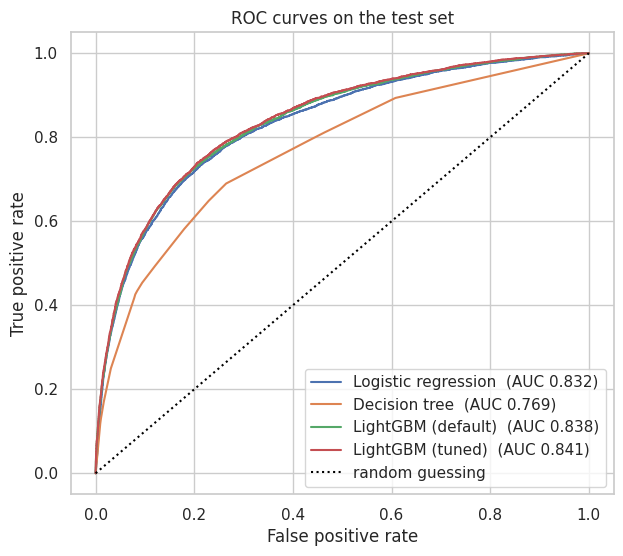

In [6]:
plt.figure(figsize=(7, 6))
for name, probs in test_probs.items():
    fpr, tpr, _ = roc_curve(y_test, probs)
    auc = roc_auc_score(y_test, probs)
    plt.plot(fpr, tpr, label=name + "  (AUC " + str(round(auc, 3)) + ")")

plt.plot([0, 1], [0, 1], ":", color="black", label="random guessing")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC curves on the test set")
plt.legend()
plt.savefig(os.path.join(FIG_DIR, "roc.png"), dpi=130, bbox_inches="tight")
plt.show()

### 1.2 Confusion matrices at the default 0.50 cut-off (test set)
Rows = what really happened, columns = what the model predicted.

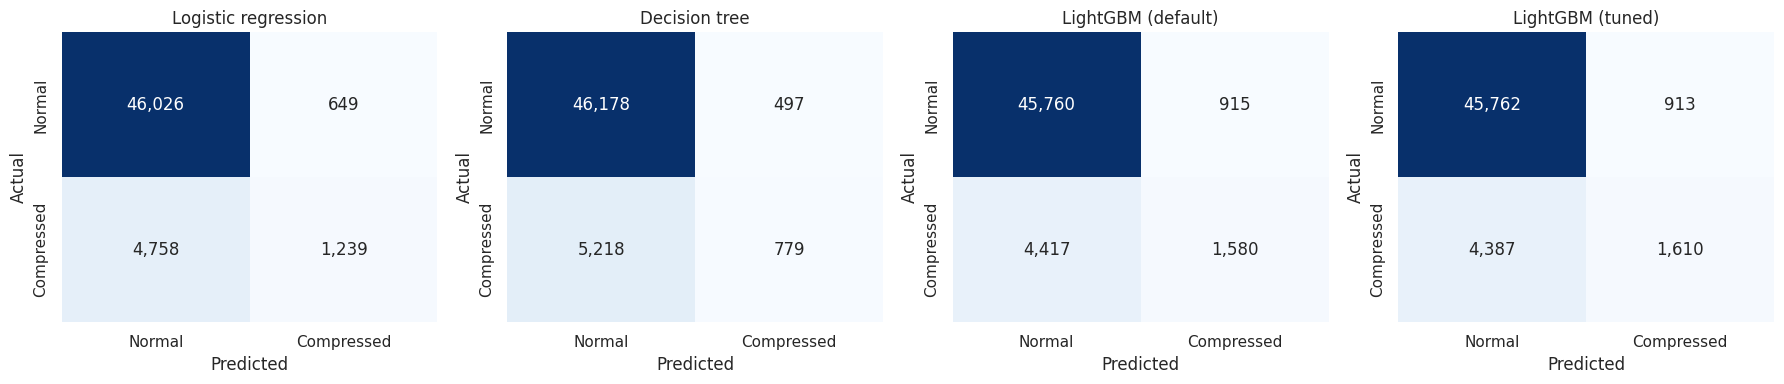

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, (name, probs) in zip(axes, test_probs.items()):
    matrix = confusion_matrix(y_test, (probs >= 0.5).astype(int))
    sns.heatmap(matrix, annot=True, fmt=",", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Normal", "Compressed"], yticklabels=["Normal", "Compressed"])
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "confusion_default.png"), dpi=130, bbox_inches="tight")
plt.show()

### 1.3 Can we trust the probabilities? (calibration)
If the model says "20% risk", about 20% of those customers should really compress. Points on the dashed diagonal mean the probabilities are trustworthy. This matters in section 3, where the cost rule needs real probabilities.

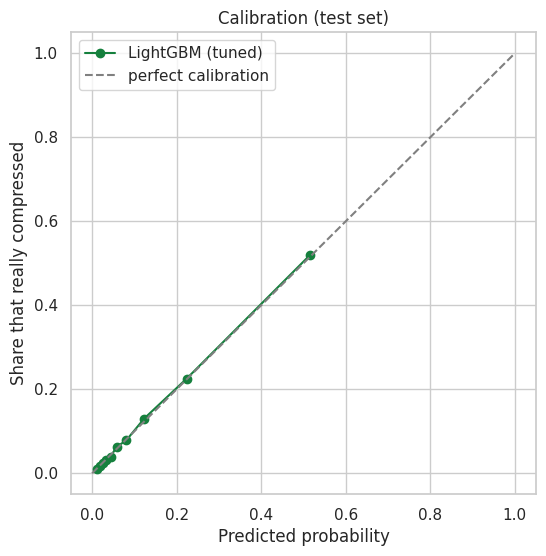

In [8]:
real_rate, predicted = calibration_curve(y_test, test_probs[CHAMPION], n_bins=10, strategy="quantile")

plt.figure(figsize=(6, 6))
plt.plot(predicted, real_rate, marker="o", color="#15803D", label=CHAMPION)
plt.plot([0, 1], [0, 1], "--", color="gray", label="perfect calibration")
plt.xlabel("Predicted probability")
plt.ylabel("Share that really compressed")
plt.title("Calibration (test set)")
plt.legend()
plt.savefig(os.path.join(FIG_DIR, "calibration.png"), dpi=130, bbox_inches="tight")
plt.show()

## 2 · Why does the champion flag a customer?
### 2.1 Feature importance
How much each feature helped the trees make better splits ("gain").

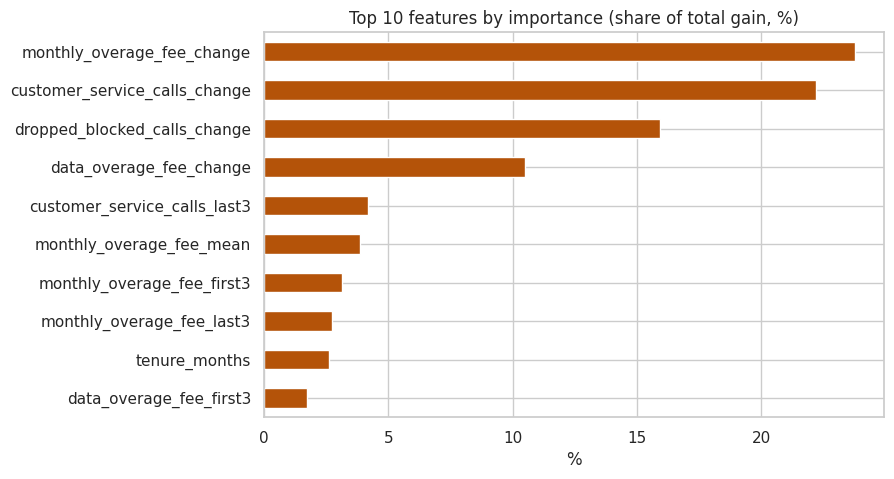

In [9]:
gain = pd.Series(champion.booster_.feature_importance(importance_type="gain"), index=features)
share = (gain / gain.sum() * 100).sort_values().tail(10)

plt.figure(figsize=(8, 5))
share.plot(kind="barh", color="#B45309")
plt.title("Top 10 features by importance (share of total gain, %)")
plt.xlabel("%")
plt.savefig(os.path.join(FIG_DIR, "importance.png"), dpi=130, bbox_inches="tight")
plt.show()

### 2.2 SHAP: direction and size of each feature's effect
SHAP gives every feature a push up or down on each customer's risk score. We use 2,000 test customers to keep it fast.
- **Bar plot:** average size of the push (importance).
- **Beeswarm:** each dot is a customer. Colour = feature value (red high, blue low). Dots to the right raise the risk.

In [10]:
sample = X_test.sample(2000, random_state=42)

explainer = shap.TreeExplainer(champion)
explanation = explainer(sample)
if explanation.values.ndim == 3:        # some SHAP versions return one set of values per class
    explanation = explanation[:, :, 1]

print("SHAP values computed:", explanation.values.shape)

SHAP values computed: (2000, 23)


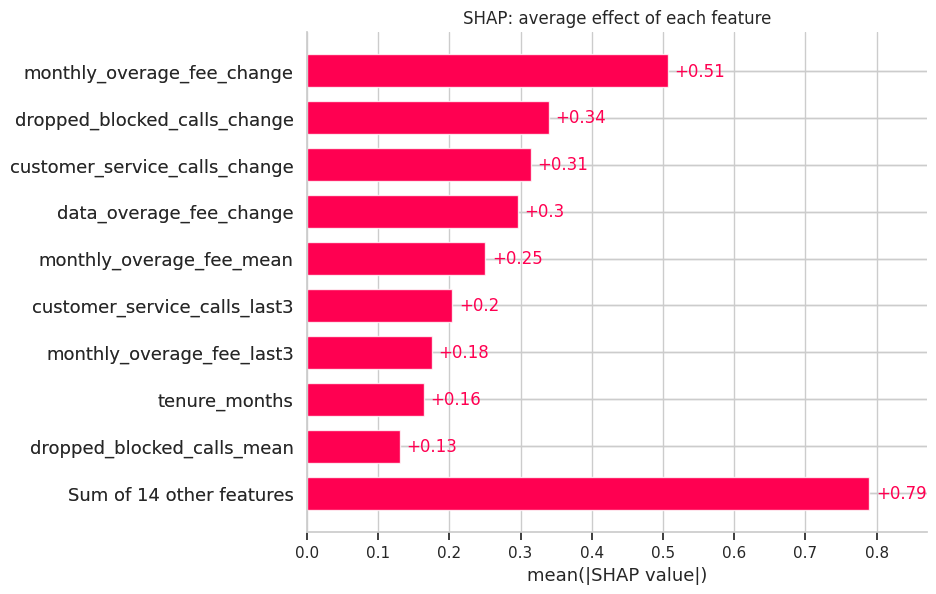

In [11]:
shap.plots.bar(explanation, max_display=10, show=False)
plt.title("SHAP: average effect of each feature")
plt.savefig(os.path.join(FIG_DIR, "shap_bar.png"), dpi=130, bbox_inches="tight")
plt.show()

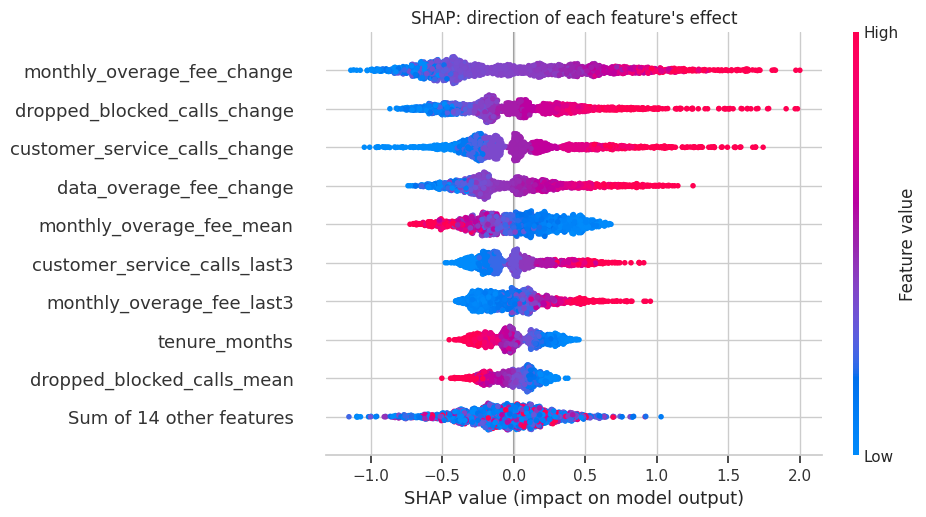

In [12]:
shap.plots.beeswarm(explanation, max_display=10, show=False)
plt.title("SHAP: direction of each feature's effect")
plt.savefig(os.path.join(FIG_DIR, "shap_beeswarm.png"), dpi=130, bbox_inches="tight")
plt.show()

**Caution when reading SHAP.** It shows each feature's effect *given the other features*. Features that carry the same information (for example `_change`, `_last3` and `_first3`) share the credit, and a feature can point in an unexpected direction (look at `monthly_overage_fee_mean`). Read SHAP as *how the model reasons*, not as cause and effect.

### 2.3 One customer's explanation
The waterfall starts at the average risk and shows how each feature moves *this* customer's score. A retention team could use this as the "reason" behind an offer. (Values are on the model's internal log-odds scale.)

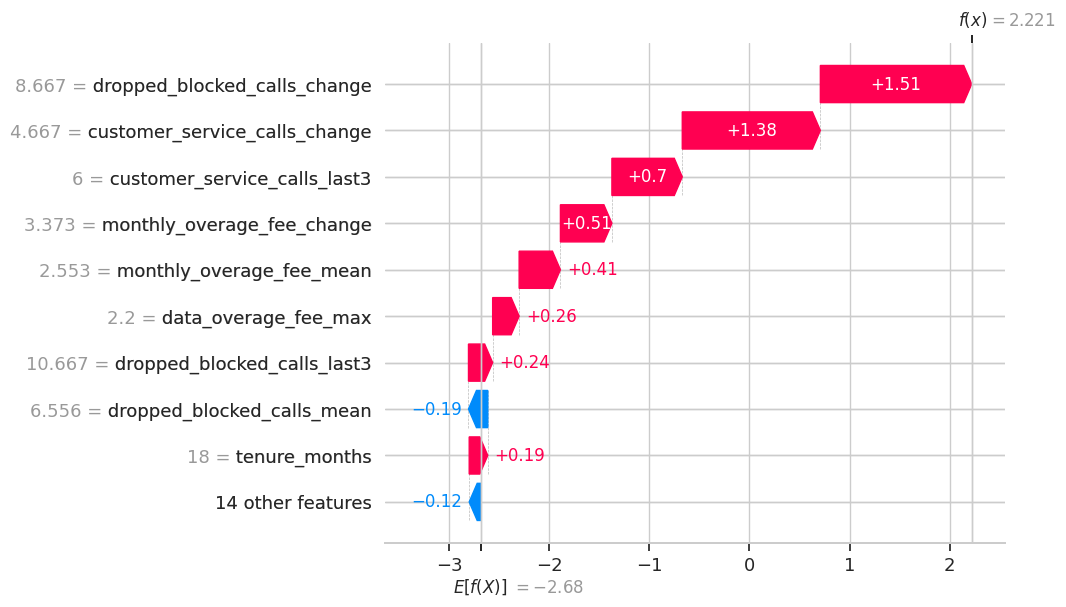

Predicted risk of this customer: 0.902


In [13]:
sample_probs = champion.predict_proba(sample)[:, 1]
example = int(np.argmax(sample_probs))        # the highest-risk customer in the sample

shap.plots.waterfall(explanation[example], max_display=10, show=False)
plt.savefig(os.path.join(FIG_DIR, "shap_waterfall.png"), dpi=130, bbox_inches="tight")
plt.show()
print("Predicted risk of this customer:", round(sample_probs[example], 3))

### 2.4 Risk by overage level
Do customers with higher recent overage fees get higher predicted risk?

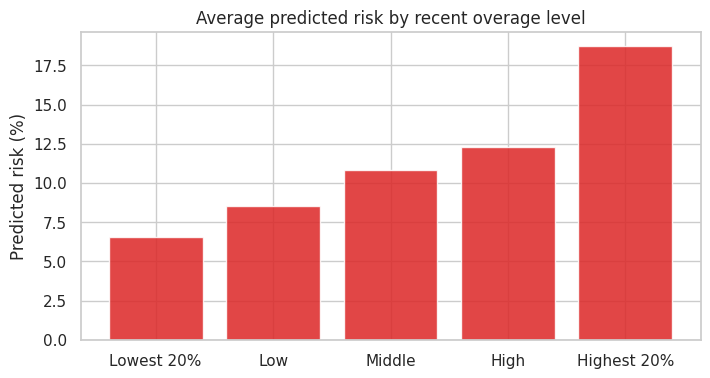

In [14]:
band = pd.qcut(X_test["monthly_overage_fee_last3"], 5,
               labels=["Lowest 20%", "Low", "Middle", "High", "Highest 20%"])
risk_by_band = pd.Series(test_probs[CHAMPION], index=X_test.index).groupby(band, observed=True).mean() * 100

plt.figure(figsize=(8, 4))
plt.bar(risk_by_band.index.astype(str), risk_by_band.values, color="#DC2626", alpha=0.85)
plt.title("Average predicted risk by recent overage level")
plt.ylabel("Predicted risk (%)")
plt.savefig(os.path.join(FIG_DIR, "risk_by_overage.png"), dpi=130, bbox_inches="tight")
plt.show()

## 3 · Turning predictions into money
### 3.1 The assumptions (change them freely)
- Sending a retention offer costs a fixed amount.
- If we correctly flag a customer who would compress, we assume the offer **saves** a fixed amount of revenue.
- If we flag a customer who would not have compressed, the offer money is wasted.

A flagged customer is worth the offer when `chance × value > cost`, so the break-even chance is `cost ÷ value`. This holds when probabilities are well calibrated (see 1.3).

In [15]:
VALUE_PER_SAVE = 500    # EGP kept when a compressing customer is retained   (assumption)
COST_PER_OFFER = 50     # EGP cost of one retention offer                     (assumption)

break_even = COST_PER_OFFER / VALUE_PER_SAVE
print("Break-even threshold = cost / value =", break_even)

Break-even threshold = cost / value = 0.1


In [16]:
def evaluate(y_true, probs, threshold):
    flagged = probs >= threshold
    tp = int((flagged & (y_true == 1)).sum())
    fp = int((flagged & (y_true == 0)).sum())
    fn = int((~flagged & (y_true == 1)).sum())
    gross = tp * VALUE_PER_SAVE
    cost = (tp + fp) * COST_PER_OFFER
    return {"threshold": round(threshold, 2), "flagged": tp + fp, "caught (TP)": tp,
            "wasted (FP)": fp, "missed (FN)": fn,
            "revenue saved": gross, "campaign cost": cost, "net value": gross - cost}

### 3.2 Choose the threshold on the validation set
We scan thresholds from 0.01 to 0.99 and keep the one with the highest **net value** on **validation**. The test set is not used to choose, so the final numbers stay honest.

In [17]:
thresholds = np.arange(0.01, 1.0, 0.01)

valid_scan = pd.DataFrame([evaluate(y_valid.values, valid_probs[CHAMPION], t) for t in thresholds])
test_scan = pd.DataFrame([evaluate(y_test.values, test_probs[CHAMPION], t) for t in thresholds])

best_threshold = float(valid_scan.loc[valid_scan["net value"].idxmax(), "threshold"])
print("Best threshold on validation:", best_threshold)

Best threshold on validation: 0.09


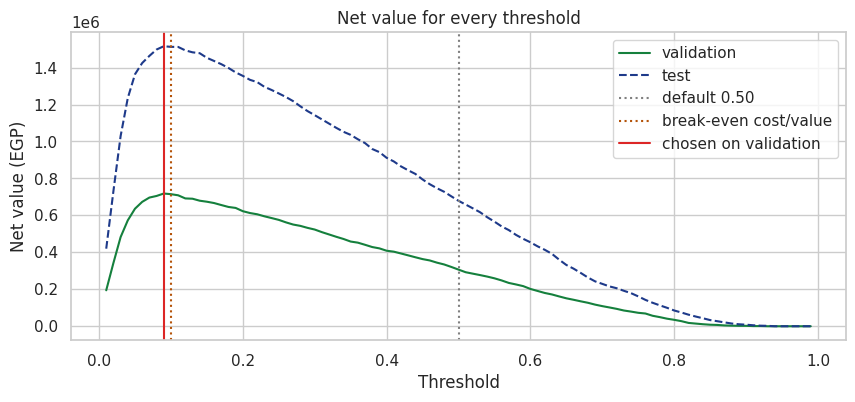

In [18]:
plt.figure(figsize=(10, 4))
plt.plot(valid_scan["threshold"], valid_scan["net value"], color="#15803D", label="validation")
plt.plot(test_scan["threshold"], test_scan["net value"], color="#1E3A8A", linestyle="--", label="test")
plt.axvline(0.5, color="gray", linestyle=":", label="default 0.50")
plt.axvline(break_even, color="#B45309", linestyle=":", label="break-even cost/value")
plt.axvline(best_threshold, color="#DC2626", label="chosen on validation")
plt.title("Net value for every threshold")
plt.xlabel("Threshold")
plt.ylabel("Net value (EGP)")
plt.legend()
plt.savefig(os.path.join(FIG_DIR, "net_value_curve.png"), dpi=130, bbox_inches="tight")
plt.show()

The test curve is higher than the validation curve only because the test set holds about twice as many customers. Compare the **shape** and where the peak sits, not the height.

### 3.3 The ledger on the test set
Three ways to pick the threshold, judged on customers the model has never seen.

In [19]:
options = {"Default 0.50": 0.50, "Break-even cost/value": break_even, "Chosen on validation": best_threshold}

ledger = pd.DataFrame([evaluate(y_test.values, test_probs[CHAMPION], t) for t in options.values()],
                      index=list(options.keys()))
ledger

,threshold,flagged,caught (TP),wasted (FP),missed (FN),revenue saved,campaign cost,net value
Default 0.50,0.50,2523,1610,913,4387,805000,126150,678850
Break-even cost/value,0.10,15360,4560,10800,1437,2280000,768000,1512000
Chosen on validation,0.09,16695,4700,11995,1297,2350000,834750,1515250


In [20]:
gain_vs_default = ledger.loc["Chosen on validation", "net value"] - ledger.loc["Default 0.50", "net value"]
print("Test customers:", len(y_test))
print("Net value gained by the chosen threshold vs 0.50:", int(gain_vs_default), "EGP (test set only)")

Test customers: 52672
Net value gained by the chosen threshold vs 0.50: 836400 EGP (test set only)


### 3.4 How sensitive is this to the "100% saved" assumption?
In real campaigns not every flagged customer accepts the offer. Here is the net value at the chosen threshold if only part of the caught customers are saved. (A lower save rate would also move the best threshold higher; we do not re-optimise here.)

In [21]:
chosen = evaluate(y_test.values, test_probs[CHAMPION], best_threshold)

rows = []
for save_rate in [1.0, 0.5, 0.25]:
    net = chosen["caught (TP)"] * save_rate * VALUE_PER_SAVE - chosen["flagged"] * COST_PER_OFFER
    rows.append({"share of caught customers saved": save_rate, "net value": int(net)})
pd.DataFrame(rows)

,share of caught customers saved,net value
0,1.00,1515250
1,0.50,340250
2,0.25,-247250


## 4 · Export the final model with joblib
We save one file that holds everything needed to score new customers: the model, the feature list, the threshold and the cost assumptions. The library versions are stored too, because a joblib file should be reloaded with the same versions.

In [22]:
package = {
    "model": champion,
    "features": features,
    "threshold": float(best_threshold),
    "value_per_save": VALUE_PER_SAVE,
    "cost_per_offer": COST_PER_OFFER,
    "lightgbm_version": lgb.__version__,
    "sklearn_version": sklearn.__version__,
    "note": "Trained on synthetic demonstration data.",
}

model_path = os.path.join(WORK_DIR, "retention_model.joblib")
joblib.dump(package, model_path)
print("Saved:", model_path, "-", round(os.path.getsize(model_path) / 1024), "KB")

Saved: work/retention_model.joblib - 986 KB


### 4.1 Reload it and test it

In [23]:
loaded = joblib.load(model_path)

new_probs = loaded["model"].predict_proba(X_test[loaded["features"]])[:, 1]
same = np.allclose(new_probs, test_probs[CHAMPION])

print("Reloaded model gives identical predictions:", same)
print("Reloaded AUC:", round(roc_auc_score(y_test, new_probs), 4))
print("Threshold stored in the file:", loaded["threshold"])

Reloaded model gives identical predictions: True
Reloaded AUC: 0.8409
Threshold stored in the file: 0.09


### 4.2 Score "new" customers
Pretend five rows from the test set are new customers. The file tells us who should get an offer.

In [24]:
new_customers = X_test.head(5)

risk = loaded["model"].predict_proba(new_customers[loaded["features"]])[:, 1]
action = np.where(risk >= loaded["threshold"], "send offer", "no offer")

pd.DataFrame({"risk": risk.round(3), "action": action}, index=new_customers.index)

,risk,action
customer_id,,
110795,0.063,no offer
110277,0.027,no offer
161016,0.043,no offer
189504,0.049,no offer
187722,0.046,no offer


### 4.3 Save the test-set predictions

In [25]:
predictions = pd.DataFrame({
    "customer_id": X_test.index,
    "risk_score": test_probs[CHAMPION],
    "flagged": (test_probs[CHAMPION] >= best_threshold).astype(int),
    "actually_compressed": y_test.values,
})
predictions.to_parquet(os.path.join(WORK_DIR, "test_predictions.parquet"), index=False)
print("Saved test_predictions.parquet:", predictions.shape)

Saved test_predictions.parquet: (52672, 4)


## 5 · Summary
- **Threshold:** the threshold chosen on validation lands very close to the break-even value (cost / value). That is what we expect when probabilities are well calibrated (section 1.3).
- **Money:** on the test set the cost-based threshold gives roughly twice the net value of the default 0.50, *if every caught customer is saved*.
- **Biggest caveat:** that assumption drives everything. Section 3.4 shows that if only a quarter of caught customers accept the offer, the campaign loses money at this threshold. A real deployment must first measure how often the offer works, for example with a held-out control group.
- **Explanations:** the model leans most on the `_change` features. Importance shows what the model uses, not what it needs (see the ablation in notebook 03).
- **Export:** the joblib file reloads and reproduces the predictions exactly.

All numbers come from synthetic data and the stated assumptions. They demonstrate the method, not a real result.